# Antoine equation parameter identification

In order to perform vapour-liquid equilibrium calculation and in addition to liquid activity coefficients, one must be able to calculate the saturated vapour pressure.

To calculate the saturated vapour pressure, we use the Antoine equation:

\begin{equation}
\log P = A - \dfrac{B}{C+T}
\end{equation}

these parameters are determined from vapour pressure data through regression. Lets look at the example of water. The data are retreieved from [NIST webbook](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Units=SI&Mask=4#Thermo-Phase)

In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import Antoine calculator
from src.pure import AntoineCalculator

# instantiate the calculator
antoine_calc = AntoineCalculator()

If we look at the table in NISTwebbok, the critical pressure is well beyond the temperature interval of validity of the provided paramters. lets choose on to verify the boiling point instead.

In [2]:
# data row: 5 T in 344 to 373
A = 5.08354
B = 1663.125
C = -45.622
Tb = 373.15  # K
P_atm = antoine_calc.antoine_correlation(A, B, C, Tb)
P_atm

1.0132809050198732

this matches well atmospheric pressure in bar.

However, these parameters might not be reported for all compounds and definetly not in a predcictive way. So far, efforts to develop group-contribution models for saturated vapour pressure has yielded little to no results.
However, from a theoretical point of view, we can - with the help of group-contribution models -  locate three distinct points on the vapour pressure curve. These are illustrated below:

![Phase Diagram](../img/phase_diagram.png)

*Figure: Vapour pressure curve showing the three distinct points that can be determined using group-contribution models*

in principle, from knowing three points on the saturated vapour pressure curve one can fit the three required parameters for the Antoine correlation. This is done by solving a system of three equations.
\begin{align}
\log_{10}(P_0) &= A - \frac{B}{C + T_b} \\
\log_{10}(P_c) &= A - \frac{B}{C + T_c} \\
\log_{10}(P_w) &= A - \frac{B}{C + 0.7 T_c}
\end{align}

Where:
- $P_0 = 1.01325$ bar (atmospheric pressure)
- $P_c$ = critical pressure [bar]
- $P_w = 10^{-(ω+1)} \cdot P_c$ (pressure at reduced temperature $T_r = 0.7$) (see definition of [ω](https://en.wikipedia.org/wiki/Acentric_factor))
- $T_b$ = boiling point [K]
- $T_c$ = critical temperature [K]
- $ω$ = acentric factor [-]
- $A$, $B$, $C$ = Antoine parameters to be solved

However, such a problem requires good initialization to solve as a feasibility (no objective function, all equations should be satisfied) rather than an optimization problem (minimzing the errors of predicted pressures). 

The work by [Thomson (1945)](https://pubs.acs.org/doi/10.1021/cr60119a001) provides a very noce analysis of the correlation as well as methods to determine the constants. The method of *selected points* suits very well to out case. 

The core of the method is that for three saturated vapour pressure points ($y_1, y_2, y_3$) at the coressponding three temperatures ($t_1, t_2, t_3$) the three parameters can be determined as follows:

\begin{align}
\dfrac{y_3-y_2}{y_2-y_1} \dfrac{t_2-t_1}{t_3-t_2} &= 1 - \frac{t_3-t_1}{t_3 + C} \\
B &= \frac{y_3-y_1}{t_3 - t_1} (t_1+C) (t_3+C) \\
A &= y_2 + \frac{B}{t_2 + C}
\end{align}

As such, the developped software does the following:
1. provide a pre-estimate of A, B, C using the selected point method
2. use these initializations to solve the system of equations.

Lets try this out now.

In [3]:
# define compound
compound = {'H2O': 1}

# instantiate property calculator
from src.pure import PropertyCalculator
pure_calc = PropertyCalculator()

# calculate the required properties
critical_props = pure_calc.calculate(compound, properties=['tc', 'pc', 'tb', 'ac'])

# solve for the Antoine parameters
results = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props)

lets check the results

In [7]:
print(results['A'])
print(results['B'])
print(results['C'])

5.276150790167597
1810.313164589222
-29.66536409838349


We can further validate the calculation by using the following

In [4]:
antoine_calc.validate_antoine_parameters(A=results['A'],
                                         B=results['B'],
                                         C=results['C'],
                                         tb=critical_props['tb'],
                                         tc=critical_props['tc'],
                                         pc=critical_props['pc'],)

{'pressure_at_boiling_point': 1.0132500000000007,
 'pressure_at_critical_temp': 220.63999999999993,
 'error_at_boiling_point': 6.661338147750939e-16,
 'error_at_critical_temp': 2.8421709430404007e-13,
 'relative_error_critical': 1.2881485419871275e-13}

we can also perform a visualization of the saturated vapour pressure.

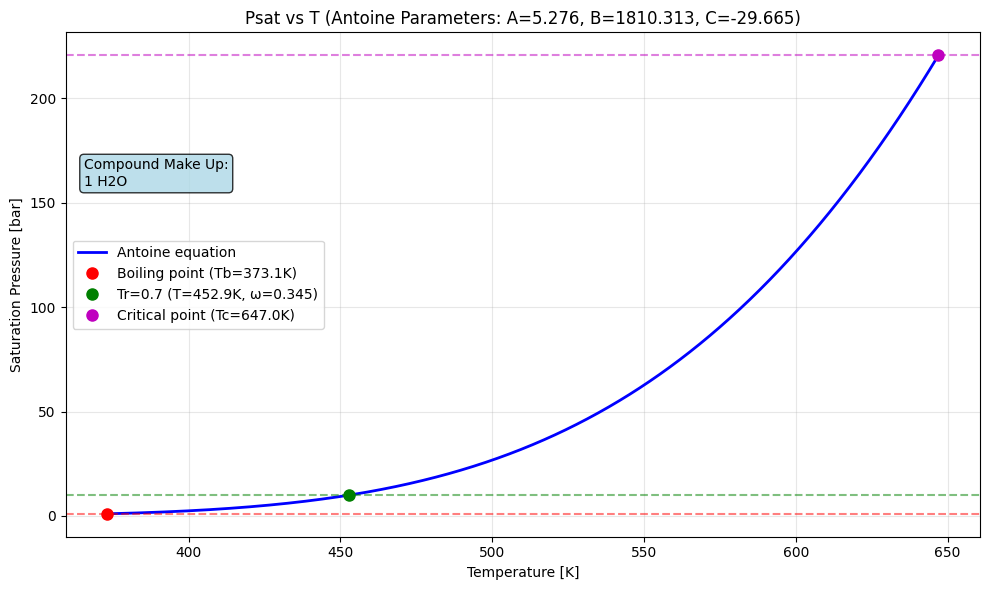

In [5]:
# import function
from src.pure.antoine_visualizations import plot_psat

plot_psat(A=results['A'],
          B=results['B'],
          C=results['C'],
          tb=critical_props['tb'],
          tc=critical_props['tc'],
          pc=critical_props['pc'],
          ac =critical_props['ac'],
          compound_name='Water',
          compound=compound)

lets us imagine for a given set of temperatures,  instead of a single temperature as before.

In [6]:
# create range of temperature:
import numpy as np
T = np.linspace(critical_props['tb'], critical_props['tc'], 100)  # K
# calculate the saturated vapour pressure
psat = antoine_calc.antoine_correlation(A=results['A'],
                                        B=results['B'],
                                        C=results['C'],
                                        T=T)